# Example of the aitlas toolbox in the context of object detection 

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import NasaMarineDebrisDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 739


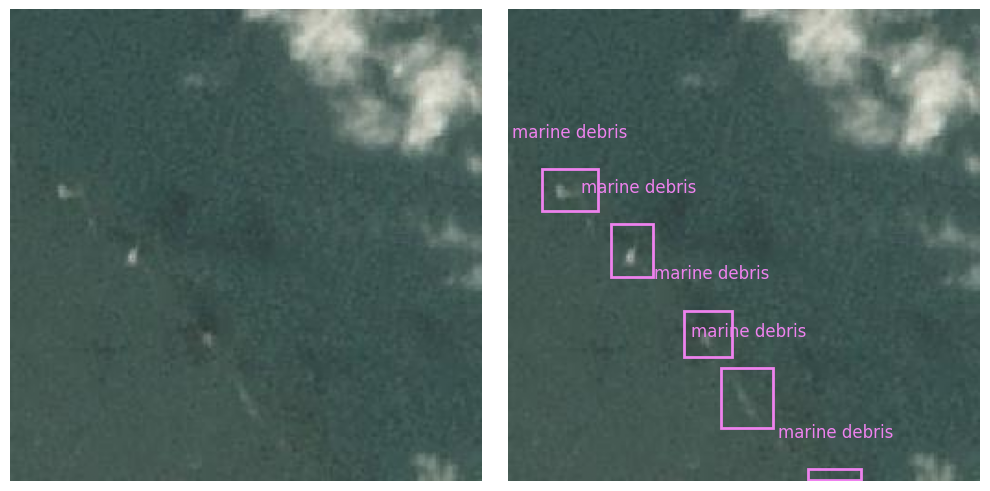

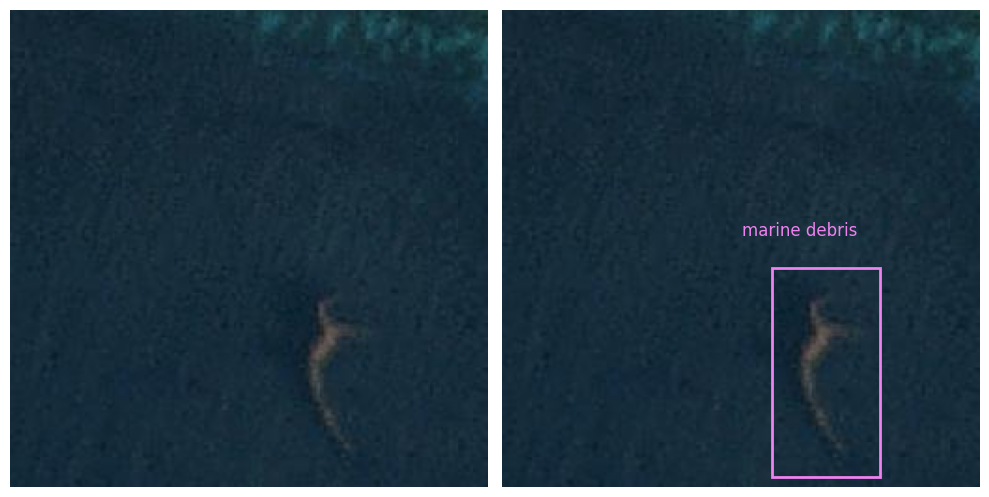

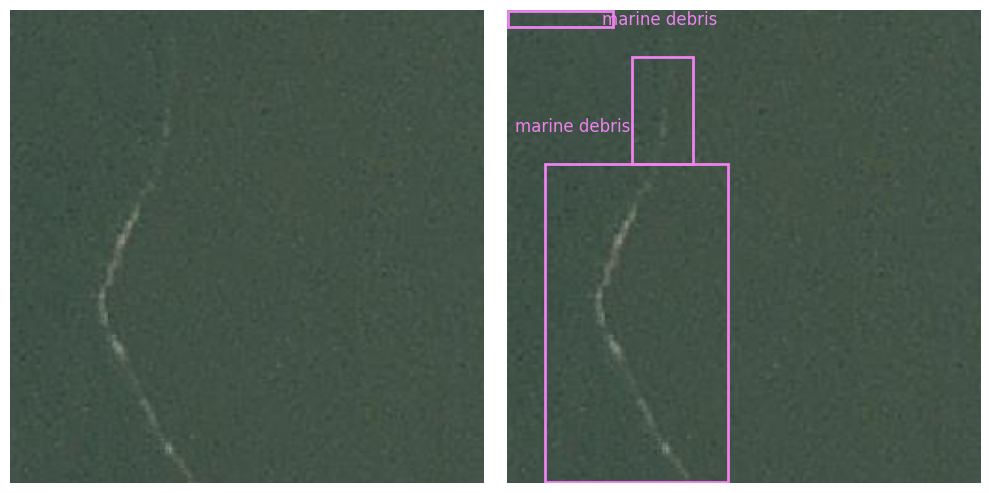

In [ ]:
dataset_config = {
    "data_dir": "./data/marine_debris/source/",
    "annotation_dir": "./data/marine_debris/labels/",
}
dataset = NasaMarineDebrisDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(5)
dataset.show_image(10)
dataset.show_image(100);

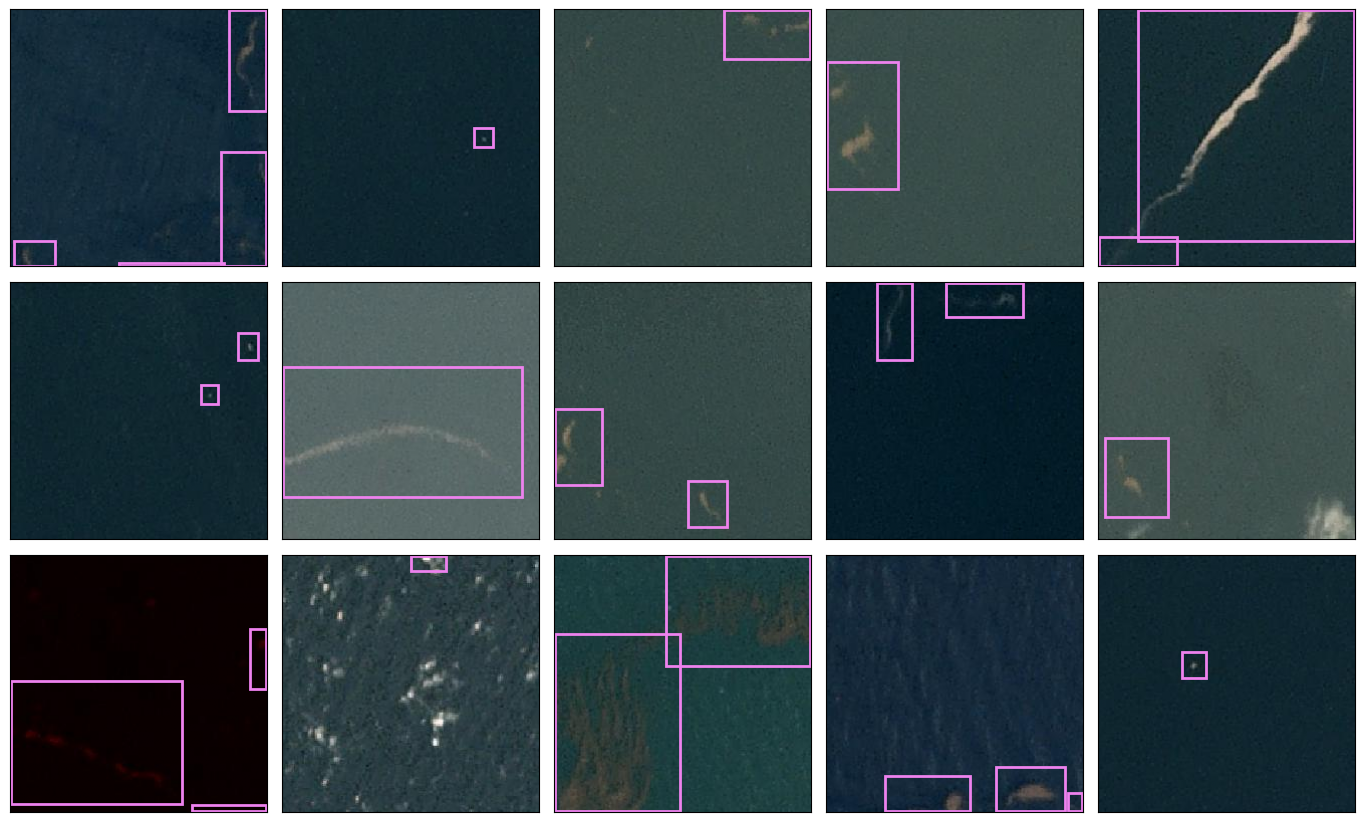

In [8]:
dataset.show_batch(15);

In [9]:
dataset.data_distribution_table()

,Label,Count
0,marine debris,1625


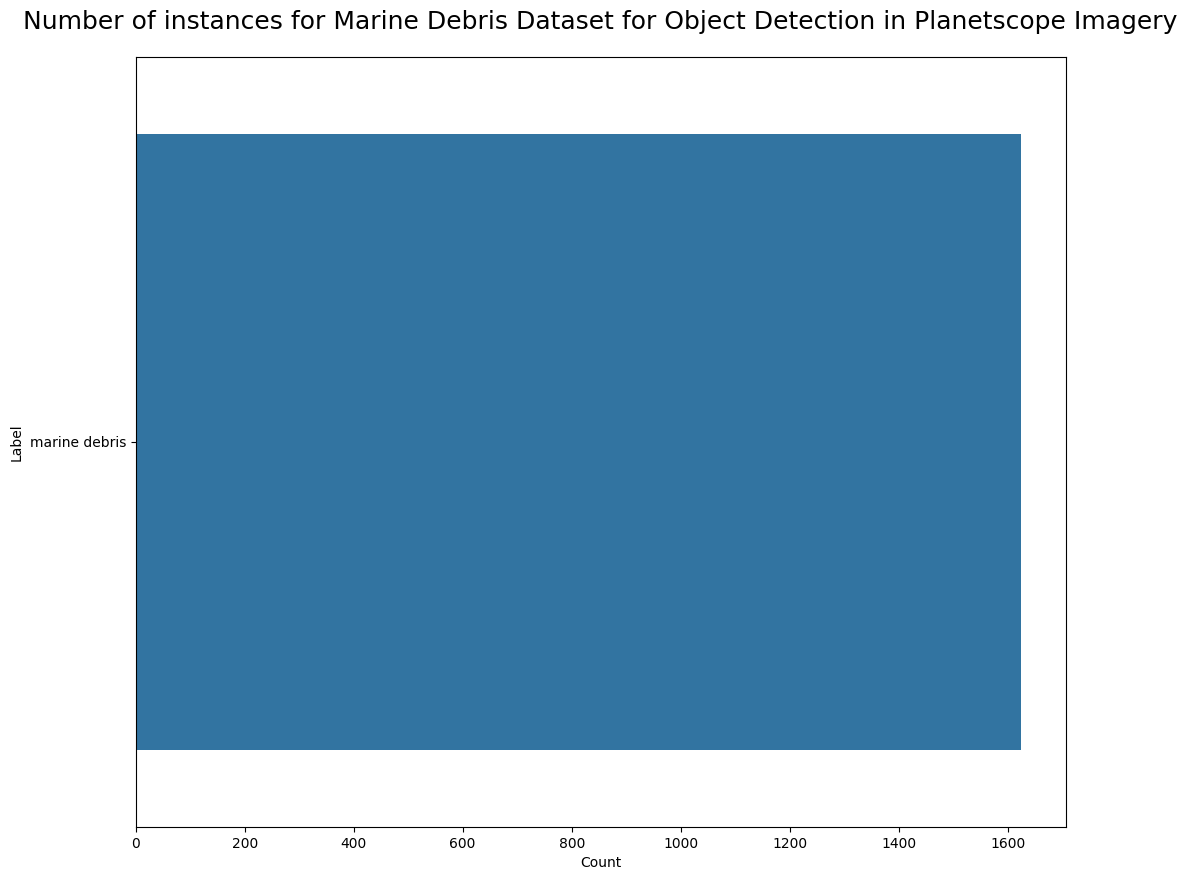

In [26]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/marine_debris/source/",
    "annotation_dir": "./data/marine_debris/labels/",
    "csv_file": "./data/marine_debris/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = NasaMarineDebrisDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 592


## Create the model

In [ ]:
epochs = 20
model_directory = "./data/experiments/marine_debris/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [23]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-07-07 08:04:52,828 INFO Starting training.
training: 100%|██████████| 74/74 [00:24<00:00,  2.97it/s]
2025-07-07 08:05:17,786 INFO epoch: 1, time: 25, loss:  0.51441
testing on train set: 100%|██████████| 74/74 [00:12<00:00,  5.73it/s]
2025-07-07 08:05:33,190 INFO map:0.16380272805690765, map_50:0.48333320021629333, map_75:0.05895065888762474, map_small:0.0022442243061959743, map_medium:0.14422862231731415, map_large:0.1999753713607788, mar_1:0.14738059043884277, mar_10:0.30446842312812805, mar_100:0.3074730336666107, mar_small:0.0063492064364254475, mar_medium:0.29818782210350037, mar_large:0.34665605425834656, map_per_class:0.16380272805690765, mar_100_per_class:0.3074730336666107, classes:1.0
training: 100%|██████████| 74/74 [00:24<00:00,  3.02it/s]
2025-07-07 08:05:57,737 INFO epoch: 2, time: 24, loss:  0.40971
testing on train set: 100%|██████████| 74/74 [00:12<00:00,  5.75it/s]
2025-07-07 08:06:11,472 INFO map:0.3121722936630249, map_50:0.6549590229988098, map_75:0.2448086887

0.05509705703101448

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/marine_debris/source/",
    "annotation_dir": "./data/marine_debris/labels/",
    "csv_file": "./data/marine_debris/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = NasaMarineDebrisDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/marine_debris/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 74


2025-07-07 08:26:34,572 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/marine_debris/checkpoint.pth.tar
2025-07-07 08:26:34,879 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/marine_debris/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 10/10 [00:02<00:00,  4.62it/s]


[{'map': 0.23510847985744476,
  'map_50': 0.4162628948688507,
  'map_75': 0.18717040121555328,
  'map_small': 0.0445544570684433,
  'map_medium': 0.2967255711555481,
  'map_large': 0.21536709368228912,
  'mar_1': 0.14935897290706635,
  'mar_10': 0.30128204822540283,
  'mar_100': 0.30128204822540283,
  'mar_small': 0.0416666679084301,
  'mar_medium': 0.36142855882644653,
  'mar_large': 0.2864864766597748,
  'map_per_class': 0.23510847985744476,
  'mar_100_per_class': 0.30128204822540283,
  'classes': 1.0}]

## Predictions

2025-07-07 08:26:38,973 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/marine_debris/checkpoint.pth.tar
2025-07-07 08:26:39,321 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/marine_debris/checkpoint.pth.tar at epoch 21


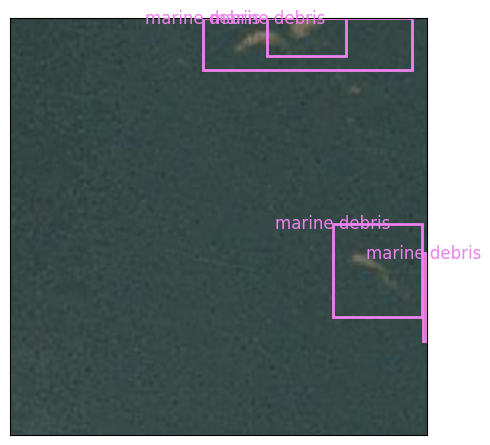

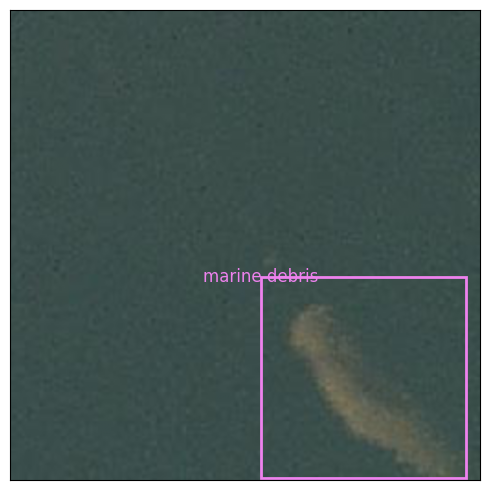

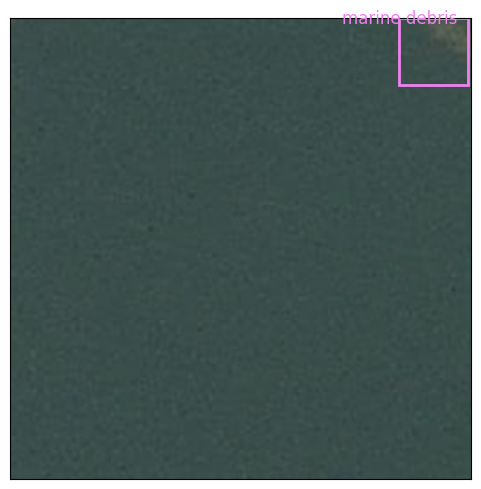

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/marine_debris/checkpoint.pth.tar"
labels = ["no-data", "marine debris"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/marine_debris/source/20181124_155715_1049_16758-29691-16.tif')
image = image.transpose(2,1,0)
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/marine_debris/source/20181124_155715_1049_16765-29691-16.tif')
image = image.transpose(2,1,0)
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/marine_debris/source/20181124_155715_1049_16766-29691-16.tif')
image = image.transpose(2,1,0)
fig = model.detect_objects(image, labels, transform)